In [1]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time
sys.path.append('../../code/pycharm')
from single_station_transient import *
from utils import *
import pickle as pkl

## Transient analysis: form queue lenght to waiting time


<div dir="rtl">

## עד עכשיו חישבנו התפלגות אורך התור ולא זמן המתנה.

### זה לא במקרה, חישוב זמן המתנה לא מוגדר היטב כאשר עושים חישוב טרזינאנטי.

### נניח צרכן מגיע בשעה 09:00, מה זמן המתנה הממוצע שלו? 

### יהיה לי קשה להעריך כמה זמן מחכה צרכן שמגיע ב09:00 כי רוב הסיכויים ששוב צרכן לא הגיע בדיוק בתדע. אני יכול לבדוק למשל כמה זמן צרכנים חיכו שהינבתן שהגיעו באיזור 09:00 למשל מ08:55 עד 09:05 אבל זה צריך להכריע מה זה הסביבה הקרובה. האם זה 10 דקות או יותר?

### ככל שאני מגדיל את הסביבה יש לי יותר נתונים אבל מצד שני זו תהיה הערכה יותר גסה, כי אולי יש הבדל גדול בין מי שמגיע ב08:55 למי למגיע ב09:05.

## Workload: 

### דרך אלגנית לפתור את זה םשוט למדוד כמה זמן עבודה נשאר במערכת בכל רגע שאנחנו מודדים.

### מהו זמן עבודה? 

### אם באותו רגע אני מגיע לצרכנים כמה זמן יעבור עד שהשרת יתפנה אלי. 

### כלומר מהו הזמן שנותר מהצרכן שכרגע בשירות + הזמן  השירות של כל מי שלפני בתור 








In [2]:
dict_sch = {0:1, 12:0.5,20:0.9}

arrival_scd_pd = convert_dict_to_pd(dict_sch)
arrival_scd_pd

,LB_time,arrival_rate
0,0.0,1.0
1,12.0,0.5
2,20.0,0.9


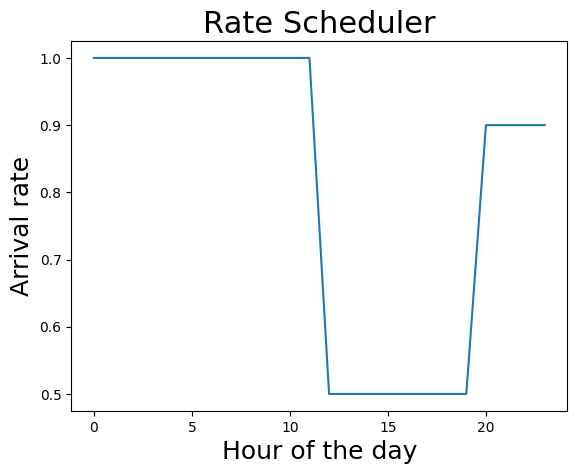

In [3]:
rates = []
for hour in range(24):
    rates.append(give_rate_per_time(arrival_scd_pd,  hour))

plt.figure()
plt.plot(np.arange(24), rates)
plt.xlabel('Hour of the day', fontsize = 18)
plt.ylabel('Arrival rate', fontsize = 18)
plt.title('Rate Scheduler', fontsize = 22)
plt.show()

In [4]:
class Queue_single_station_waiting_time:

    def __init__(self, arrival_scd_pd, mu, sim_time):

        self.env = simpy.Environment() # initializing simpy enviroment 
        self.server = simpy.Resource(self.env, capacity=1) # Defining a resource with capacity 1
        self.end_time = sim_time # The time simulation terminate
        self.id_current = 1 # keeping track of cusotmers id
        self.df_events = pd.DataFrame([]) # is a dataframe the holds all information of the queue dynamic:
        #an event can one of three: (1. arrival, 2. entering service 3. service completion)
        
        self.df_waiting_times = pd.DataFrame([]) # is a dataframe the holds all information waiting time
        self.mu = mu # service rate
        self.num_cust_sys = 0 # keeping track of number of customers in the system
        
        self.service_times = {}
        self.event_log_customer_id_list = []
        self.event_log_num_cust_list = []
        self.event_log_type_list = []
        self.event_log_time_stamp = []
        
        self.arrival_pd = arrival_scd_pd

    def run(self):

        self.env.process(self.customer_arrivals()) ## Initializing a process
        self.env.run(until=self.end_time) ## Running the simulaiton until self.end_time

   
    
    def give_rate_per_time(self, time):
        
        ind_rate = self.arrival_pd.loc[self.arrival_pd['LB_time']<=time, :].index[-1]
        return self.arrival_pd.loc[ind_rate, 'arrival_rate']
        
    
    #########################################################
    ################# Service block ######################### 
    ######################################################### 
    
    
    def service(self, customer):

        with self.server.request() as req:
                       

            yield req

            self.event_log_customer_id_list.append(customer.id) 
            self.event_log_time_stamp.append(self.env.now)     
            self.event_log_num_cust_list.append(self.num_cust_sys)
            self.event_log_type_list.append('Start service')
            
            yield self.env.timeout(customer.service_time)


            #we compute how much time the system had this number of customers
            
            self.num_cust_sys -= 1 # updating number of cusotmers in the system
 
            self.event_log_customer_id_list.append(customer.id)
            self.event_log_time_stamp.append(self.env.now)
            self.event_log_num_cust_list.append(self.num_cust_sys)
            self.event_log_type_list.append('Departure')
                       

           

    #########################################################
    ################# Arrival block ######################### 
    ######################################################### 
    
    
    def customer_arrivals(self):

        while True:

            arrival_rate = self.give_rate_per_time(self.env.now) 
            
            yield self.env.timeout(np.random.exponential(1/arrival_rate))


            
            curr_id = self.id_current
            arrival_time = self.env.now
            service_time = np.random.exponential(1/self.mu)
            customer = Customer(curr_id, arrival_time, 1, service_time)
            self.service_times[curr_id] = service_time
            
            self.event_log_customer_id_list.append(customer.id) 
            self.event_log_time_stamp.append(self.env.now)
            
      
            
            self.num_cust_sys += 1
            self.event_log_num_cust_list.append(self.num_cust_sys)
            self.event_log_type_list.append('Arrival')

            self.id_current += 1



            self.env.process(self.service(customer))

class Customer:
    def __init__(self, id, arrival_time, station, service_time):
        self.id = id
        self.arrival_time = arrival_time
        self.station = station
        self.service_time = service_time

In [5]:
lamda = 1
mu  = 1
sim_time = 20


sim_time +=1
sim_instance = Queue_single_station_waiting_time(arrival_scd_pd, mu, sim_time)
sim_instance.run()

In [6]:
event_log = pd.DataFrame({'Customer_id': sim_instance.event_log_customer_id_list,
                                  'Time_stamp': sim_instance.event_log_time_stamp,
                                  'Type': sim_instance.event_log_type_list,
                                  'num_cust': sim_instance.event_log_num_cust_list})

In [7]:
event_log.head()

,Customer_id,Time_stamp,Type,num_cust
0,1,1.754861,Arrival,1
1,1,1.754861,Start service,1
2,1,2.252586,Departure,0
3,2,2.602867,Arrival,1
4,2,2.602867,Start service,1


<div dir="rtl">

### על ידי סימולציה בודדת ניתן רק לראות ריאליזציה אחת. אם נרצה לדעת תכונות סטטיסטיות כמו תוחלת מספר הצרכנים ברגע 5 או ההתפלגות נצטרך לעשות הרבה סימולציות.
    
### נעשה עכשיו 5000 סימולציות ונחשב ססטיטיקות של כמה צרכנים היו בכל רגע נתון. 

In [8]:
def get_workload(sim_instance, time_points=range(1, 21)):

    df = pd.DataFrame({
        'Customer_id': sim_instance.event_log_customer_id_list,
        'Time_stamp': sim_instance.event_log_time_stamp,
        'Type': sim_instance.event_log_type_list,
        'num_cust': sim_instance.event_log_num_cust_list
    })

    arrivals = (
        df[df["Type"] == "Arrival"]
        .set_index("Customer_id")["Time_stamp"]
        .to_dict()
    )

    starts = (
        df[df["Type"] == "Start service"]
        .set_index("Customer_id")["Time_stamp"]
        .to_dict()
    )

    service_times = sim_instance.service_times

    workload = {}

    for t in time_points:

        W = 0.0

        for customer, arrival in arrivals.items():

            if arrival > t:
                continue

            s = service_times[customer]

            if customer not in starts or starts[customer] > t:
                # Customer is waiting at time t
                W += s

            else:
                # Customer has started service
                elapsed = t - starts[customer]

                # If service hasn't finished, add residual
                W += max(s - elapsed, 0.0)

        workload[t] = W

    return workload

get_workload(sim_instance)

{1: 0.0,
 2: 0.25258580934679087,
 3: 1.0937908203713933,
 4: 0.09379082037139364,
 5: 0.0,
 6: 0.0,
 7: 5.367098705341773,
 8: 5.142384369142971,
 9: 4.142384369142972,
 10: 3.1423843691429716,
 11: 2.6672564308479374,
 12: 3.744030484986473,
 13: 3.836390300175154,
 14: 3.118631605763875,
 15: 2.1186316057638748,
 16: 1.1186316057638748,
 17: 0.11863160576387416,
 18: 0.0,
 19: 0.0,
 20: 0.0}

In [9]:
def give_workload_per_sim(lamda, mu, sim_time):
    
    sim_instance = Queue_single_station_waiting_time(arrival_scd_pd, mu, sim_time)
    sim_instance.run()

    return get_workload(sim_instance)

In [ ]:
list_of_sims = []
for ind in tqdm(range(50000)):

    list_of_sims.append(give_workload_per_sim(lamda, mu, sim_time))
    

 98%|█████████████████████████████████████████████████████████████████████████████▍ | 49033/50000 [09:35<00:05, 170.26it/s]

In [ ]:
time_dict = {}

for time in range(1, sim_time):
    time_dict[time] = []

for time in tqdm(range(1, sim_time )):
    for sim in list_of_sims:
        time_dict[time].append(sim[time]) 

In [ ]:
plt.figure()
plt.title('Workload distribution at time = 3', fontsize = 20, fontweight = 'bold')
plt.hist(time_dict[3], density = True, bins = 400)
plt.show()

<div dir="rtl">

## Inflated zero:

### נשים לב למשהו מיוחד בהסטוגרמה הזאת.

### יש לנו ערכים רציפים לאורך התחום אבל יש קו גדול מאד על 0. 

### יש לנו בעצם התפלגות מיוחדת שהיא לא רציפה ולא בדידה, אלא עירוב שלהם.

### אנחנו יכולים להיות 0 בהסתברות חיובית כלומר גדולה ממש מ-0 ואילו שאר הערכים מתנהגים כמו כל התפלגות רציפה. 

### זה משהו שכדאי שיחק בחשבון כאשר אנחנו עושים אנליזה. יש לנו מסה בערך מסוים במקרה הזה בדיוק בערך 0. 

In [ ]:
mean_values = []

for time in range(1, 21):
    mean_values.append(np.array(time_dict[time]).mean())



In [ ]:
plt.figure()
plt.plot(np.arange(1,21), mean_values)
plt.xlabel('Time', fontsize = 18, fontweight = 'bold')
plt.ylabel('Average workload', fontsize = 18, fontweight = 'bold')

plt.show()

<div dir="rtl">

## ואם נרצה לחשב את ההסתברות שהמערכת תהיה ריקה כלומר workload = 0 כפונקציה של הזמן:

In [ ]:
zero_workload = []

for time in range(1, 21):
    zero_workload.append((np.array(time_dict[time])==0).mean().item())

In [ ]:
plt.figure()
plt.plot(np.arange(1,21), zero_workload)
plt.xlabel('Time', fontsize = 18, fontweight = 'bold')
plt.ylabel('P(workload=0)', fontsize = 18, fontweight = 'bold')

plt.show()

<div dir="rtl">

## למה הגרף הזה מעניין?

### הוא עוזר לנו להבין מתי המערכת עמודה ומתי לא. באיזורים שההסתברות לworkload ברמה אפסית אולי נרצה לנווט יותר מטופלים כך שברגעי עומס תהיה הקלה. 

### או לחילופין אפשר להוריד כוח אדם בזמן הזה. 